<a href="https://colab.research.google.com/github/alreemoeed/image_processing/blob/main/Lab8_Morphological_ipynb_txt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

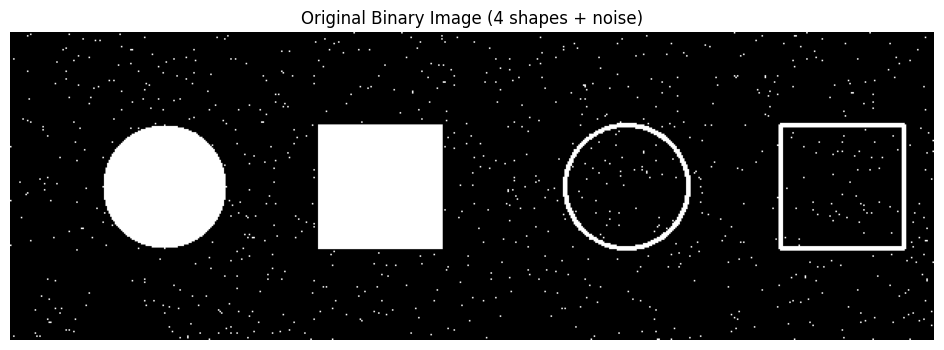

In [8]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)
cv2.circle(image, (400, 100), 40, 255, 2)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)

np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [9]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



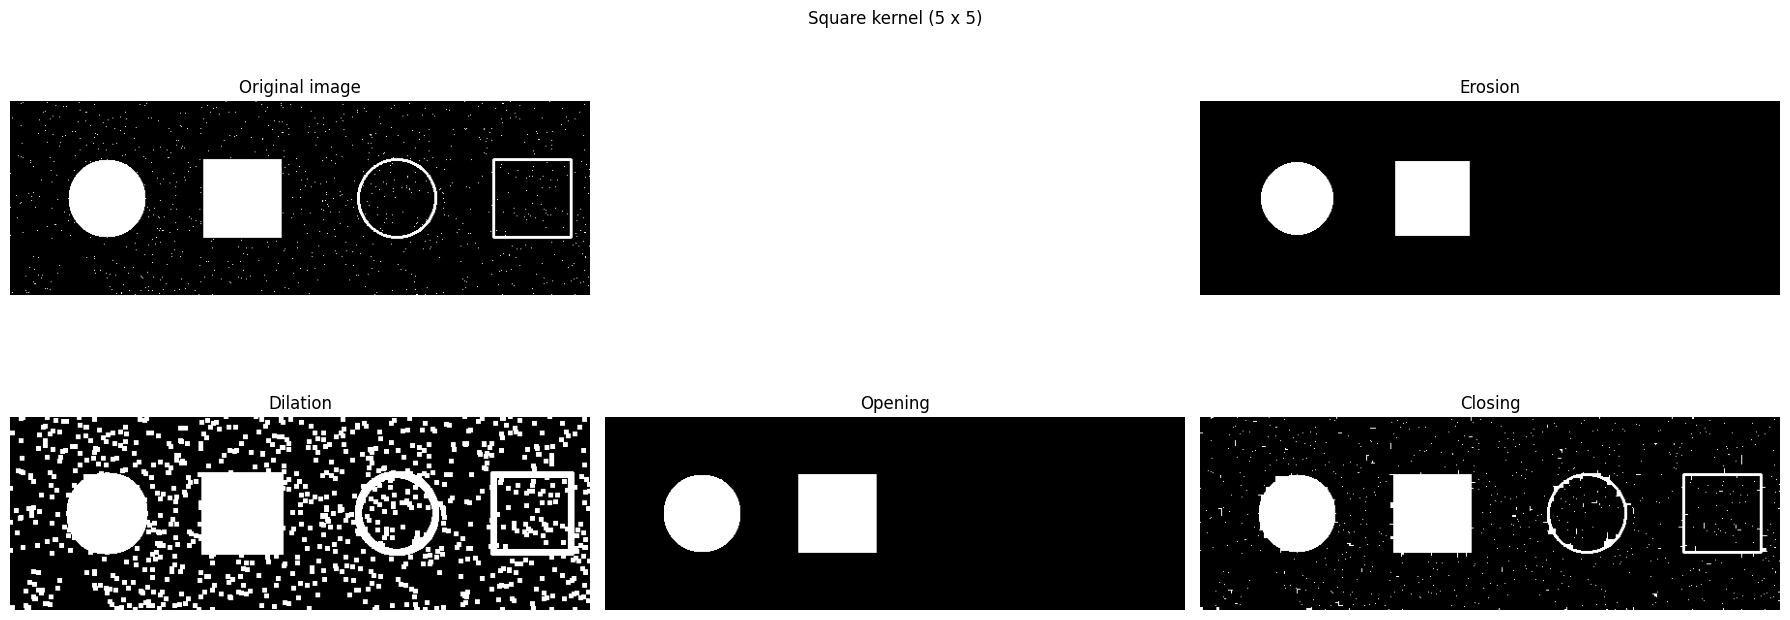

In [10]:
# Apply the four operations using the 5 x 5 square kernel.
erosion_square = cv2.erode(image, kernel, iterations=1)
dilation_square = cv2.dilate(image, kernel, iterations=1)
opening_square = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closing_square = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

fig, axes = plt.subplots(2, 3, figsize=(18, 7))
results = [image, kernel, erosion_square, dilation_square,
           opening_square, closing_square]
titles = ['Original image', 'Square kernel (5 x 5)', 'Erosion',
          'Dilation', 'Opening', 'Closing']
for ax, result, title in zip(axes.flat, results, titles):
    ax.imshow(result, cmap='gray', vmin=0, vmax=1 if result is kernel else 255)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()


## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

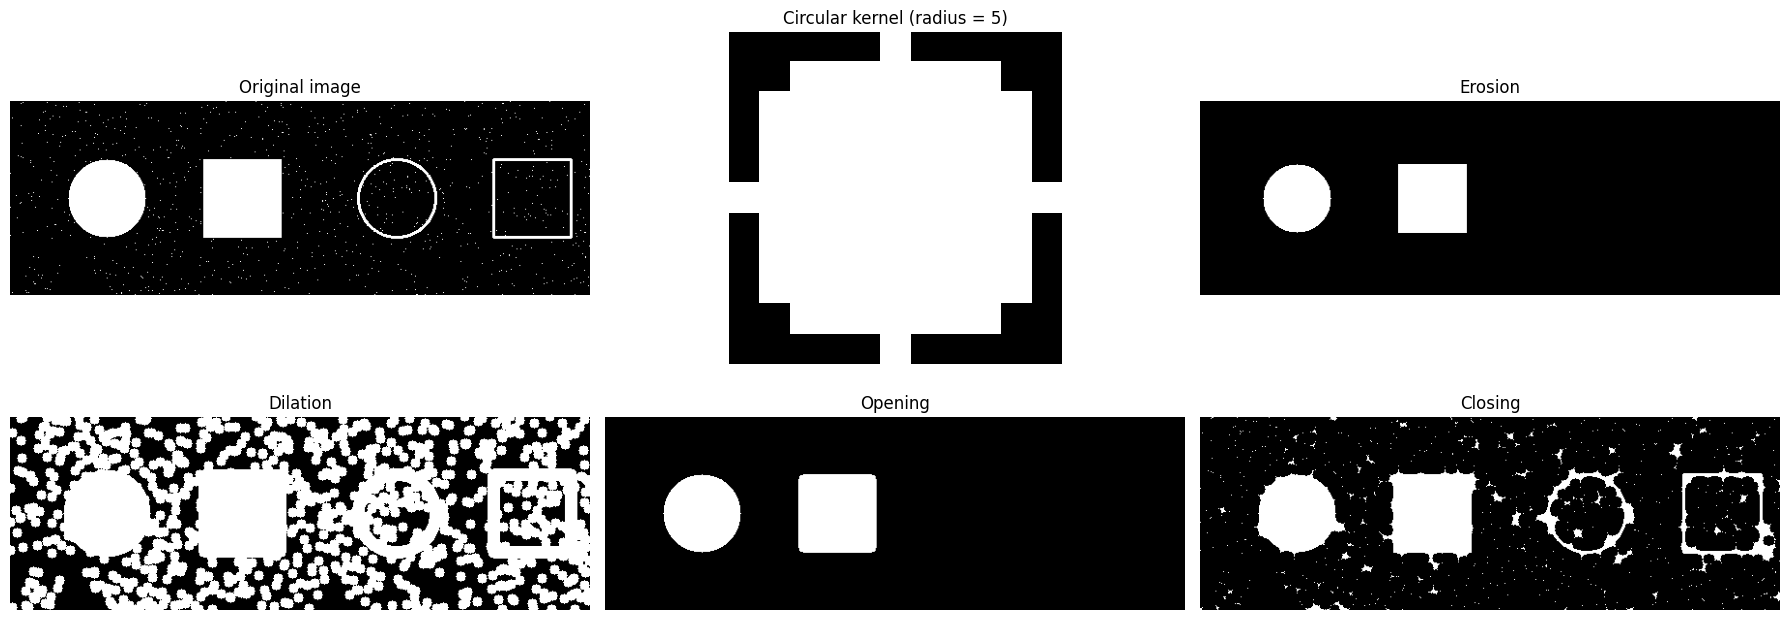

In [11]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)
    return kernel

radius = 5
circle_kernel = circular_structuring_element(radius)

# Apply the operations to the same original image.
erosion_circle = cv2.erode(image, circle_kernel, iterations=1)
dilation_circle = cv2.dilate(image, circle_kernel, iterations=1)
opening_circle = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closing_circle = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

fig, axes = plt.subplots(2, 3, figsize=(18, 7))
results = [image, circle_kernel, erosion_circle, dilation_circle,
           opening_circle, closing_circle]
titles = ['Original image', 'Circular kernel (radius = 5)', 'Erosion',
          'Dilation', 'Opening', 'Closing']
for ax, result, title in zip(axes.flat, results, titles):
    ax.imshow(result, cmap='gray', vmin=0,
              vmax=1 if result is circle_kernel else 255)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()


## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2



The square kernel gives the boundaries a more block-like shape, especially when isolated noise pixels are dilated into small squares. The circular kernel produces rounder boundaries and turns isolated noise pixels into small disks. It generally preserves circular outlines better, while the square kernel fits straight edges and square corners better.

Erosion shrinks the filled shapes and removes the thin hollow outlines with both kernels. Dilation thickens the shapes and also enlarges the noise. Opening removes the small white noise, but it also removes the thin hollow outlines because they cannot contain either kernel. Closing bridges small gaps and thickens or connects nearby foreground regions; it does not fill the large empty centers of the hollow shapes with these kernel sizes.

The circular kernel has radius 5, so its size is 11 x 11, while the square kernel is only 5 x 5. The circular kernel therefore produces stronger shrinking and expansion and can bridge larger gaps. The differences here depend on both the kernel shape and its size, so this is not a comparison of shape alone.
